# Просмотр карт ambientCG

Первые шесть превью Dataset Viewer. Одноканальные изображения преобразуются в RGB для отображения.

In [1]:
from io import BytesIO
from textwrap import fill
import requests
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np

repo = "dream-textures/textures-color-1k"
params = dict(dataset=repo, config="default", split="train", offset=0, length=6)
response = requests.get("https://datasets-server.huggingface.co/rows", params=params, timeout=60)
response.raise_for_status()
revision = response.headers.get("X-Revision", "unknown")
samples = []
for entry in response.json()["rows"]:
    row = entry["row"]
    result = requests.get(row["image"]["src"], timeout=60)
    result.raise_for_status()
    samples.append(dict(image=Image.open(BytesIO(result.content)).copy(), text=row["text"]))
assert len(samples) == 6
print("Ревизия:", revision)

Ревизия: 33c49b76fcf3a18b0d521d8e760c88d49f3e47bc


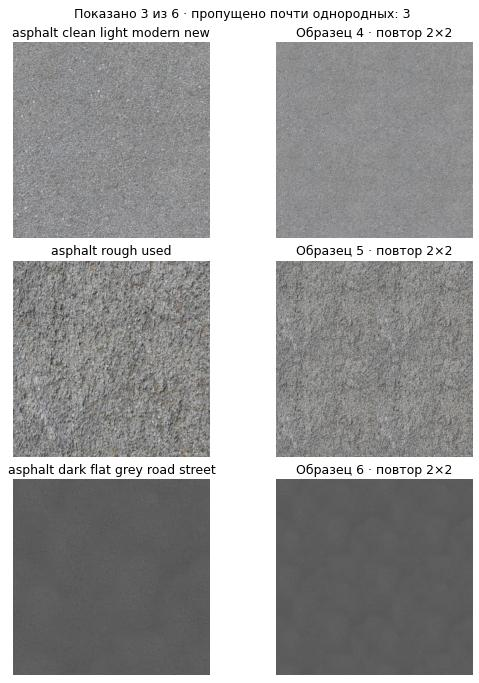

In [2]:
visible = []
for index, sample in enumerate(samples, start=1):
    image = sample["image"]
    caption = sample["text"]
    if not isinstance(caption, str) or not caption.strip():
        raise ValueError(f"Запись {index}: отсутствует подпись")
    if image.mode not in ("L", "RGB") or image.size != (512, 512):
        raise ValueError(f"Запись {index}: {image.mode}, {image.size}")
    image = image.convert("RGB")
    pixels = np.asarray(image)
    gray = np.asarray(image.convert("L"))
    if np.median(gray) < 80:
        low, high = np.percentile(gray, [1, 99])
        if high <= low:
            continue
        pixels = np.clip((pixels.astype(float) - low) / (high - low), 0, 1)
        caption += " · контраст P1–P99"
    visible.append((index, caption, pixels))

if not visible:
    raise ValueError("В выборке нет карт с различимой фактурой")
fig, axes = plt.subplots(len(visible), 2, squeeze=False, figsize=(7, 3 * len(visible)), constrained_layout=True)
fig.suptitle(f"Показано {len(visible)} из {len(samples)} · пропущено почти однородных: {len(samples) - len(visible)}")
for (index, caption, pixels), (left, right) in zip(visible, axes):
    left.imshow(pixels)
    left.set_title(fill(caption, 44))
    right.imshow(np.tile(pixels, (2, 2, 1)))
    right.set_title(f"Образец {index} · повтор 2×2")
    left.axis("off")
    right.axis("off")
from pathlib import Path
import json

fig.savefig("ambientcg.jpg", dpi=75, bbox_inches="tight")
Path("preview.json").write_text(json.dumps({"revision": revision, "captions": [r["text"] for r in samples]}))
plt.show()